# WildLens Ensemble Training and Evaluation

## Section 1: Install

In [1]:
!pip install -q -U ultralytics supervision scikit-learn ensemble-boxes
!pip install -q rfdetr==1.10.1  # version the RF-DETR-M checkpoint was saved with

## Section 2: Imports

In [2]:
import os
import asyncio
import time
import pickle
import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import supervision as sv
import yaml
from IPython.display import display
from PIL import Image
from google.colab import userdata, files
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from supervision.metrics import MeanAveragePrecision
from ultralytics import YOLO, RTDETR
from rfdetr import from_checkpoint
from ensemble_boxes import weighted_boxes_fusion

## Section 3: API Key

In [3]:
os.environ['ULTRALYTICS_API_KEY'] = userdata.get('ULTRALYTICS_API_KEY')
assert os.environ.get('ULTRALYTICS_API_KEY'), 'Add ULTRALYTICS_API_KEY to Colab Secrets first.'

## Section 4: Dataset

In [4]:
uploaded = files.upload()
ndjson_files = [name for name in uploaded if name.lower().endswith('.ndjson')]
assert len(ndjson_files) == 1, f'Upload exactly one .ndjson file; found {len(ndjson_files)}.'
NDJSON_PATH = os.path.abspath(ndjson_files[0])

from ultralytics.data.converter import convert_ndjson_to_yolo

def _convert_ndjson_in_worker():
    return asyncio.run(
        convert_ndjson_to_yolo(NDJSON_PATH, output_path='/content/converted_datasets')
    )

with ThreadPoolExecutor(max_workers=1) as executor:
    DATA = str(executor.submit(_convert_ndjson_in_worker).result())

DATASET_DIR = Path(DATA).parent
names = yaml.safe_load(open(DATA))['names']
CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
NC = len(CLASS_NAMES)
print(f'Converted dataset YAML: {DATA}')
print('Classes:', CLASS_NAMES)

Saving isy5002-g14-dataset.ndjson to isy5002-g14-dataset (1).ndjson
Converting isy5002-g14-dataset (1).ndjson fraction=1.0 → /content/converted_datasets/isy5002-g14-dataset (1)-e1fa4d7c using 2652 train, 332 val, 331 test images: 100% ━━━━━━━━━━━━ 3315/3315 4.4Kit/s 0.7s
Converted dataset YAML: /content/converted_datasets/isy5002-g14-dataset (1)-e1fa4d7c/data.yaml
Classes: ['buffalo', 'elephant', 'rhino', 'zebra', 'okapi', 'leopard', 'cheetah']


## Section 5: Upload Model Weights

In [5]:
LOCAL_WEIGHTS = {'YOLO11n': '/content/y6_best.pt', 'YOLO26l': '/content/yl1_best.pt',
                 'RT-DETR-L': '/content/r6_best.pt', 'RF-DETR-M': '/content/rfdetr_best.pth'}

for name, target in LOCAL_WEIGHTS.items():
    if os.path.exists(target):
        print(f'{name}: already uploaded ({target})')
        continue
    print(f'Upload the weights file for {name}')
    uploaded = files.upload()
    assert len(uploaded) == 1, f'Upload exactly one file for {name}; found {len(uploaded)}.'
    src = os.path.abspath(next(iter(uploaded)))
    shutil.move(src, target)
    print(f'Saved {os.path.basename(src)} -> {target} ({os.path.getsize(target) / 1e6:.1f} MB)')

YOLO11n: already uploaded (/content/y6_best.pt)
YOLO26l: already uploaded (/content/yl1_best.pt)
RT-DETR-L: already uploaded (/content/r6_best.pt)
Upload the weights file for RF-DETR-M


Saving rfdetr_erasing_10_best.pth to rfdetr_erasing_10_best.pth
Saved rfdetr_erasing_10_best.pth -> /content/rfdetr_best.pth (133.9 MB)


## Section 6: Config

In [6]:
FINAL_CONF = {'YOLO11n': 0.50, 'YOLO26l': 0.50, 'RT-DETR-L': 0.70, 'RF-DETR-M': 0.45}  # final threshold of each detector
CANDIDATE_CONF = 0.02     # boxes kept as ensemble inputs
NMS_IOU = 0.70            # per-view, per-class NMS before TTA merge (removes duplicate DETR queries)
TTA_IOU = 0.55            # WBF IoU for merging view A and view B of one detector
CLUSTER_IOU = 0.55        # boxes from different detectors with IoU >= this are the same animal
MATCH_IOU = 0.50          # IoU for counting a detection as correct in evaluation
THRESHOLDS = np.round(np.arange(0.04, 0.97, 0.02), 2)  # thresholds tried for best F1
SEED = 42
RESULTS_DIR = Path('/content/ensemble_results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_NAMES = list(LOCAL_WEIGHTS)

## Section 7: Load Detectors

In [7]:
class Detector:
    def __init__(self, name, weights):
        self.name = name
        if weights.endswith('.pth'):
            self.kind, self.model = 'rfdetr', from_checkpoint(weights)
        elif name.startswith('RT-DETR'):
            self.kind, self.model = 'ultralytics', RTDETR(weights)
        else:
            self.kind, self.model = 'ultralytics', YOLO(weights)

    def predict(self, bgr, conf):
        if self.kind == 'ultralytics':
            b = self.model.predict(bgr, conf=conf, verbose=False)[0].boxes
            return b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)
        det = self.model.predict(Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)), threshold=conf)
        return valid((det.xyxy.astype(float), det.confidence.astype(float), det.class_id.astype(int)))

def valid(pred):
    # Keep only class indices 0..NC-1 (RF-DETR can output an extra, unused class index at very low confidence)
    xyxy, s, c = pred
    k = (c >= 0) & (c < NC)
    return xyxy[k], s[k], c[k]

detectors = {name: Detector(name, path) for name, path in LOCAL_WEIGHTS.items()}
for name, det in detectors.items():
    if det.kind == 'ultralytics':
        model_names = [det.model.names[i] for i in sorted(det.model.names)]
        assert model_names == CLASS_NAMES, f'{name} class order {model_names} != {CLASS_NAMES}'
print('Loaded:', list(detectors))

/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:639: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:639: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:639: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-24 13:15:09] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-24 13:15:09] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

Loaded: ['YOLO11n', 'YOLO26l', 'RT-DETR-L', 'RF-DETR-M']


## Section 8: Run Detectors on Original and Flipped Images

In [8]:
def load_split(split):
    img_dir = DATASET_DIR / 'images' / split
    for img_path in sorted(p for p in img_dir.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}):
        bgr = cv2.imread(str(img_path))
        h, w = bgr.shape[:2]
        lbl = DATASET_DIR / 'labels' / split / (img_path.stem + '.txt')
        rows = np.loadtxt(lbl, ndmin=2) if lbl.exists() and lbl.stat().st_size else np.zeros((0, 5))
        cls = rows[:, 0].astype(int)
        cx, cy, bw, bh = rows[:, 1] * w, rows[:, 2] * h, rows[:, 3] * w, rows[:, 4] * h
        gt = np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], 1) if len(rows) else np.zeros((0, 4))
        yield img_path, bgr, gt, cls

def unflip(xyxy, width):
    out = xyxy.copy()
    out[:, 0], out[:, 2] = width - xyxy[:, 2], width - xyxy[:, 0]
    return out

def run_split(split):
    path = RESULTS_DIR / f'predictions_{split}.pkl'
    if path.exists():
        records = pickle.load(open(path, 'rb'))
        for r in records:
            for view in ('A', 'B'):
                r[view] = {n: valid(p) for n, p in r[view].items()}
        missing = [n for n in detectors if n not in records[0]['A']]
        for name in missing:  # a detector added after the cache was saved: run only that detector
            print(f'{split}: running {name} (not in cache)')
            for r in records:
                bgr = cv2.imread(r['image']); w = r['w']
                det = detectors[name]
                t = time.perf_counter(); r['A'][name] = det.predict(bgr, 0.001); r['tA'][name] = time.perf_counter() - t
                t = time.perf_counter(); b = det.predict(cv2.flip(bgr, 1), 0.001); r['tB'][name] = time.perf_counter() - t
                r['B'][name] = (unflip(b[0], w), b[1], b[2])
        if missing:
            pickle.dump(records, open(path, 'wb'))
        return records
    records = []
    for k, (img_path, bgr, gt, gcls) in enumerate(load_split(split), 1):
        h, w = bgr.shape[:2]
        flipped = cv2.flip(bgr, 1)
        rec = {'image': str(img_path), 'w': w, 'h': h, 'gt': gt, 'gcls': gcls, 'A': {}, 'B': {}, 'tA': {}, 'tB': {}}
        for name, det in detectors.items():
            t = time.perf_counter(); rec['A'][name] = det.predict(bgr, 0.001); rec['tA'][name] = time.perf_counter() - t
            t = time.perf_counter(); b = det.predict(flipped, 0.001); rec['tB'][name] = time.perf_counter() - t
            rec['B'][name] = (unflip(b[0], w), b[1], b[2])
        records.append(rec)
        if k % 50 == 0:
            print(f'{split}: {k} images')
    pickle.dump(records, open(path, 'wb'))
    return records

cache = {split: run_split(split) for split in ['val', 'test']}
for split, recs in cache.items():
    print(f'{split}: {len(recs)} images, {sum(len(r["gt"]) for r in recs)} animals')

# Class indices each detector predicts with confidence >= 0.5 on validation (all must be 0..6)
for n in MODEL_NAMES:
    ids = np.concatenate([r['A'][n][2][r['A'][n][1] >= 0.5] for r in cache['val']])
    u, cnt = np.unique(ids, return_counts=True)
    print(f'{n:10s}', {int(a): int(b) for a, b in zip(u, cnt)})

[2026-10-24 13:15:14] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


val: 50 images
val: 100 images
val: 150 images
val: 200 images
val: 250 images
val: 300 images
test: 50 images
test: 100 images
test: 150 images
test: 200 images
test: 250 images
test: 300 images
val: 332 images, 457 animals
test: 331 images, 474 animals
YOLO11n    {0: 47, 1: 44, 2: 55, 3: 98, 4: 71, 5: 61, 6: 66}
YOLO26l    {0: 48, 1: 45, 2: 54, 3: 100, 4: 70, 5: 60, 6: 69}
RT-DETR-L  {0: 51, 1: 49, 2: 55, 3: 118, 4: 69, 5: 65, 6: 73}
RF-DETR-M  {0: 53, 1: 43, 2: 56, 3: 98, 4: 70, 5: 63, 6: 67}


## Section 9: Evaluation Metrics

In [9]:
def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def match(boxes, scores, classes, gt, gcls):
    # Returns each prediction's outcome ('correct' / 'wrong' / 'fp') and the unmatched ground-truth mask
    iou = iou_matrix(boxes, gt)
    used = np.zeros(len(gt), bool)
    outcome = np.empty(len(boxes), object)
    for i in np.argsort(-scores):
        cand = np.where(~used)[0]
        if len(cand) and iou[i, cand].max() >= MATCH_IOU:
            j = cand[iou[i, cand].argmax()]; used[j] = True
            outcome[i] = 'correct' if classes[i] == gcls[j] else 'wrong'
        else:
            outcome[i] = 'fp'
    return outcome, ~used

def evaluate(records, preds, thr, times):
    # preds: per image (xyxy, scores, classes); counts use scores >= thr; mAP uses all scores
    tot = {'correct': 0, 'wrong': 0, 'fp': 0, 'missed': 0}
    n_gt = 0
    for r, (b, s, c) in zip(records, preds):
        n_gt += len(r['gt'])
        k = s >= thr
        out, missed = match(b[k], s[k], c[k], r['gt'], r['gcls'])
        for o in out:
            tot[o] += 1
        tot['missed'] += int(missed.sum())
    P = [sv.Detections(xyxy=b.reshape(-1, 4), confidence=s, class_id=c) for b, s, c in preds]
    T = [sv.Detections(xyxy=r['gt'].reshape(-1, 4), class_id=r['gcls']) for r in records]
    m = MeanAveragePrecision().update(P, T).compute()
    prec = tot['correct'] / max(tot['correct'] + tot['wrong'] + tot['fp'], 1)
    rec = tot['correct'] / max(n_gt, 1)
    return {'mAP50': float(m.map50), 'mAP50-95': float(m.map50_95), 'Recall': rec, 'Precision': prec,
            'F1': 2 * prec * rec / max(prec + rec, 1e-9), 'Correct': tot['correct'], 'Wrong': tot['wrong'],
            'FP': tot['fp'], 'Missed': tot['missed'], 'Threshold': thr, 'ms/image': 1000 * float(np.mean(times))}

## Section 10: Individual Detectors on Validation

In [10]:
val_check = {n: evaluate(cache['val'], [r['A'][n] for r in cache['val']], FINAL_CONF[n], [r['tA'][n] for r in cache['val']])
             for n in MODEL_NAMES}
pd.DataFrame(val_check).T[['mAP50', 'mAP50-95', 'Recall', 'Precision']].round(3)

,mAP50,mAP50-95,Recall,Precision
YOLO11n,0.963,0.763,0.917,0.948
YOLO26l,0.963,0.789,0.937,0.960
RT-DETR-L,0.967,0.795,0.932,0.940
RF-DETR-M,0.983,0.897,0.952,0.950


## Section 11: Per-View NMS

In [11]:
def filt(pred, conf):
    xyxy, s, c = pred
    k = s >= conf
    return xyxy[k], s[k], c[k]

def nms(pred, iou_thr=NMS_IOU):
    b, s, c = pred
    order = np.argsort(-s); b, s, c = b[order], s[order], c[order]
    keep, removed = [], np.zeros(len(s), bool)
    for i in range(len(s)):
        if removed[i]:
            continue
        keep.append(i)
        rest = np.where((c == c[i]) & ~removed & (np.arange(len(s)) > i))[0]
        if len(rest):
            removed[rest[iou_matrix(b[i:i + 1], b[rest])[0] >= iou_thr]] = True
    keep = np.array(keep, int)
    return b[keep], s[keep], c[keep]

## Section 12: Un-flip and WBF (TTA Merge)

In [12]:
def merge_views(a, b, w, h):
    scale = np.array([w, h, w, h], float)
    boxes, scores, labels = [], [], []
    for xyxy, s, c in (a, b):
        nb = np.clip(xyxy / scale, 0, 1)
        k = (nb[:, 2] > nb[:, 0]) & (nb[:, 3] > nb[:, 1])  # drop boxes with zero area after clipping
        boxes.append(nb[k].tolist()); scores.append(s[k].tolist()); labels.append(c[k].tolist())
    if sum(len(s) for s in scores) == 0:
        return np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)
    fb, fs, fl = weighted_boxes_fusion(boxes, scores, labels, iou_thr=TTA_IOU, skip_box_thr=CANDIDATE_CONF, conf_type='avg')
    return np.asarray(fb) * scale, np.asarray(fs), np.asarray(fl).astype(int)

VIEWS = {}
for split in ['val', 'test']:
    for n in MODEL_NAMES:
        VIEWS[n, 'off', split] = [nms(filt(r['A'][n], CANDIDATE_CONF)) for r in cache[split]]
        VIEWS[n, 'on', split] = [merge_views(nms(filt(r['A'][n], CANDIDATE_CONF)), nms(filt(r['B'][n], CANDIDATE_CONF)), r['w'], r['h'])
                                 for r in cache[split]]

## Section 13: Effect of TTA per Detector

In [13]:
val = cache['val']; test = cache['test']
tta_effect = {}
for n in MODEL_NAMES:
    for mode in ['off', 'on']:
        tta_effect[n, mode] = evaluate(val, VIEWS[n, mode, 'val'], FINAL_CONF[n], [0])
tta_table = pd.DataFrame({f'{n}': {'mAP50-95 without TTA': tta_effect[n, 'off']['mAP50-95'],
                                   'mAP50-95 with TTA': tta_effect[n, 'on']['mAP50-95']} for n in MODEL_NAMES}).T
tta_table['TTA helps'] = tta_table['mAP50-95 with TTA'] > tta_table['mAP50-95 without TTA']
TTA_AUTO = {n: 'on' if tta_table.loc[n, 'TTA helps'] else 'off' for n in MODEL_NAMES}
QUALITY = {n: tta_effect[n, 'off']['mAP50-95'] for n in MODEL_NAMES}  # detector quality: vote weight and box priority
RANK = sorted(MODEL_NAMES, key=lambda n: -QUALITY[n])
tta_table.to_csv(RESULTS_DIR / 'tta_effect_val.csv')
print('Detector ranking by validation mAP50-95:', RANK)
print('TTA auto:', TTA_AUTO)
tta_table.round(4)

Detector ranking by validation mAP50-95: ['RF-DETR-M', 'RT-DETR-L', 'YOLO26l', 'YOLO11n']
TTA auto: {'YOLO11n': 'on', 'YOLO26l': 'on', 'RT-DETR-L': 'off', 'RF-DETR-M': 'off'}


,mAP50-95 without TTA,mAP50-95 with TTA,TTA helps
YOLO11n,0.7577,0.7613,True
YOLO26l,0.7826,0.7855,True
RT-DETR-L,0.7936,0.7602,False
RF-DETR-M,0.8931,0.8754,False


## Section 14: Cross-Detector Grouping and Species Vote

In [14]:
from itertools import combinations

def iou1(a, b):
    return iou_matrix(a[None], b[None])[0, 0]

def fuse(per_model, members):
    items = sorted(((s, n, b, c) for n in members for b, s, c in zip(*per_model[n])), key=lambda t: -t[0])
    groups = []
    for s, n, b, c in items:
        best, best_iou = None, CLUSTER_IOU
        for g in groups:
            if n in g['m']:
                continue
            v = iou1(b, g['box'])
            if v >= best_iou:
                best, best_iou = g, v
        if best is None:
            groups.append({'m': {n: (s, b, c)}, 'box': b.copy()})
        else:
            best['m'][n] = (s, b, c)
            w = np.array([m[0] for m in best['m'].values()]); bx = np.array([m[1] for m in best['m'].values()])
            best['box'] = (w[:, None] * bx).sum(0) / w.sum()
    out = []
    for g in groups:
        votes = np.zeros(NC)
        for n, (s, _, c) in g['m'].items():
            votes[c] += s * QUALITY[n]
        cls = int(votes.argmax())
        top = next(n for n in RANK if n in g['m'])
        mb = np.array([m[1] for m in g['m'].values()])
        confs = [g['m'].get(n, (0.0,))[0] for n in members]
        feats = confs + [len(g['m']) / len(members), np.mean([m[2] == cls for m in g['m'].values()]),
                         iou_matrix(mb, g['box'][None]).mean(), votes[cls] / max(votes.sum(), 1e-9), max(confs)]
        feats += list(np.eye(NC)[cls])
        out.append({'box_weighted': g['box'], 'box_best': g['m'][top][1], 'cls': cls, 'feats': np.array(feats, float),
                    'mean': float(sum(confs) / len(members)), 'max': float(max(confs))})
    return out

## Section 15: Build Ensemble Groups

In [15]:
def build(members, tta_mode, split):
    t0 = time.perf_counter()
    mode = lambda n: tta_mode if tta_mode in ('on', 'off') else TTA_AUTO[n]
    per_image = [{n: VIEWS[n, mode(n), split][i] for n in members} for i in range(len(cache[split]))]
    groups = [fuse(pm, members) for pm in per_image]
    fuse_ms = 1000 * (time.perf_counter() - t0) / len(groups)
    infer = np.array([sum(r['tA'][n] + (r['tB'][n] if mode(n) == 'on' else 0) for n in members) for r in cache[split]])
    return groups, 1000 * infer.mean() + fuse_ms

## Section 16: Box and Score Fusion

In [16]:
def to_preds(groups, box_mode, scores):
    return [(np.array([f[f'box_{box_mode}'] for f in g]).reshape(-1, 4), sc, np.array([f['cls'] for f in g], int))
            for g, sc in zip(groups, scores)]

## Section 17: Stacking Layer

In [17]:
def labels_for(groups, records, box_mode):
    y = []
    for g, r in zip(groups, records):
        if not g:
            continue
        b = np.array([f[f'box_{box_mode}'] for f in g]); c = np.array([f['cls'] for f in g]); s = np.array([f['mean'] for f in g])
        out, _ = match(b, s, c, r['gt'], r['gcls'])
        y += [o == 'correct' for o in out]
    return np.array(y, int)

def unflatten(groups, flat):
    out, i = [], 0
    for g in groups:
        out.append(flat[i:i + len(g)]); i += len(g)
    return out


def make_stacker():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))

## Section 18: Threshold Selection (Best F1)

In [18]:
def best_threshold(records, preds):
    best = (-1, 0.5)
    for t in THRESHOLDS:
        tot = {'correct': 0, 'wrong': 0, 'fp': 0}; n_gt = 0
        for r, (b, s, c) in zip(records, preds):
            n_gt += len(r['gt']); k = s >= t
            out, _ = match(b[k], s[k], c[k], r['gt'], r['gcls'])
            for o in out: tot[o] += 1
        p = tot['correct'] / max(sum(tot.values()), 1); rc = tot['correct'] / max(n_gt, 1)
        f1 = 2 * p * rc / max(p + rc, 1e-9)
        if f1 > best[0]:
            best = (f1, float(t))
    return best[1]

## Section 19: Configurations

In [19]:
configs = []
for k in range(1, len(MODEL_NAMES) + 1):
    for members in combinations(MODEL_NAMES, k):
        for tta in (['off', 'on'] if k == 1 else ['off', 'on', 'auto']):
            if k == 1:
                configs.append((members, tta, 'best', 'max'))
            else:
                for box in ['weighted', 'best']:
                    for score in ['mean', 'max', 'stacking']:
                        configs.append((members, tta, box, score))
print(len(configs), 'configurations')

built = {}
def get_groups(members, tta, split):
    key = (members, tta, split)
    if key not in built:
        built[key] = build(list(members), tta, split)
    return built[key]

206 configurations


## Section 20: Configuration Search (Validation)

In [20]:
rows, cv = [], StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for i, (members, tta, box, score) in enumerate(configs, 1):
    groups, ms = get_groups(members, tta, 'val')
    if score == 'stacking':
        X = np.array([f['feats'] for g in groups for f in g]); y = labels_for(groups, val, box)
        flat = cross_val_predict(make_stacker(), X, y, cv=cv, method='predict_proba')[:, 1]
        scores = unflatten(groups, flat)
    else:
        scores = [np.array([f[score] for f in g]) for g in groups]
    preds = to_preds(groups, box, scores)
    thr = best_threshold(val, preds)
    m = evaluate(val, preds, thr, [0])
    rows.append({'Detectors': ' + '.join(members), 'n': len(members), 'TTA': tta, 'Box': box if len(members) > 1 else '-',
                 'Score': score if len(members) > 1 else 'confidence', 'Threshold': thr, 'mAP50-95': m['mAP50-95'], 'mAP50': m['mAP50'],
                 'F1': m['F1'], 'Recall': m['Recall'], 'Precision': m['Precision'], 'ms/image': ms, 'config': (members, tta, box, score)})
    if i % 10 == 0:
        print(f'{i}/{len(configs)} done')

search = pd.DataFrame(rows)
search['Selection score'] = (search['mAP50-95'] + search['F1']) / 2
search = search.sort_values('Selection score', ascending=False).reset_index(drop=True)
search.drop(columns='config').to_csv(RESULTS_DIR / 'search_val.csv', index=False)
display(search.drop(columns='config').head(15).style.format({c: '{:.4f}' for c in ['mAP50-95', 'mAP50', 'F1', 'Recall', 'Precision', 'Selection score']} | {'ms/image': '{:.0f}', 'Threshold': '{:.2f}'}))

10/206 done
20/206 done
30/206 done
40/206 done
50/206 done
60/206 done
70/206 done
80/206 done
90/206 done
100/206 done
110/206 done
120/206 done
130/206 done
140/206 done
150/206 done
160/206 done
170/206 done
180/206 done
190/206 done
200/206 done


,Detectors,n,TTA,Box,Score,Threshold,mAP50-95,mAP50,F1,Recall,Precision,ms/image,Selection score
0,YOLO26l + RT-DETR-L + RF-DETR-M,3,off,best,mean,0.52,0.8977,0.9857,0.9668,0.9562,0.9776,165,0.9323
1,YOLO26l + RT-DETR-L + RF-DETR-M,3,auto,best,mean,0.50,0.8982,0.9859,0.9657,0.9540,0.9776,194,0.9319
2,YOLO11n + YOLO26l + RT-DETR-L + RF-DETR-M,4,off,best,mean,0.58,0.8961,0.9851,0.9641,0.9409,0.9885,191,0.9301
3,YOLO11n + YOLO26l + RT-DETR-L + RF-DETR-M,4,auto,best,mean,0.38,0.8956,0.9860,0.9637,0.9584,0.9690,233,0.9296
4,YOLO11n + YOLO26l + RF-DETR-M,3,auto,best,mean,0.34,0.8939,0.9867,0.9647,0.9562,0.9733,148,0.9293
5,YOLO26l + RF-DETR-M,2,auto,best,mean,0.38,0.8972,0.9861,0.9614,0.9540,0.9689,110,0.9293
6,YOLO11n + YOLO26l + RF-DETR-M,3,auto,best,max,0.60,0.8948,0.9844,0.9627,0.9606,0.9648,148,0.9287
7,YOLO26l + RF-DETR-M,2,off,best,mean,0.38,0.8966,0.9851,0.9604,0.9562,0.9647,81,0.9285
8,YOLO26l + RF-DETR-M,2,auto,best,max,0.60,0.8945,0.9840,0.9613,0.9519,0.9710,110,0.9279
9,RT-DETR-L + RF-DETR-M,2,off,best,mean,0.50,0.8963,0.9839,0.9591,0.9497,0.9688,133,0.9277


## Section 21: Best Configuration

In [21]:
ens = search[search.n > 1]
BEST = ens.iloc[0]
print('Best ensemble configuration (validation):', BEST['Detectors'], '| TTA', BEST['TTA'], '| box', BEST['Box'], '| score', BEST['Score'],
      f"| threshold {BEST['Threshold']:.2f}")
best_single_val = search[search.n == 1].iloc[0]
print('Best single detector configuration (validation):', best_single_val['Detectors'], '| TTA', best_single_val['TTA'])

Best ensemble configuration (validation): YOLO26l + RT-DETR-L + RF-DETR-M | TTA off | box best | score mean | threshold 0.52
Best single detector configuration (validation): RF-DETR-M | TTA off


## Section 22: Search Figures

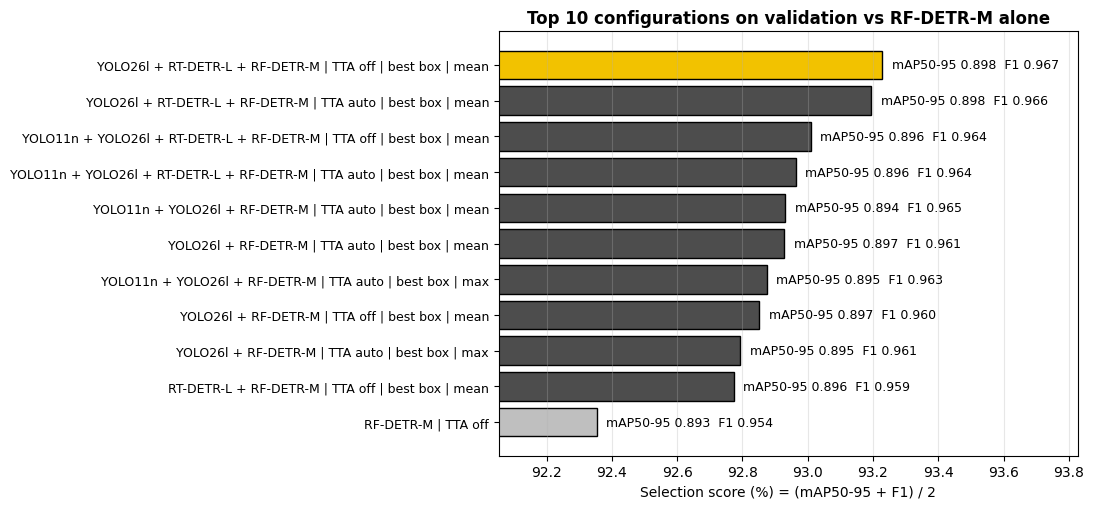

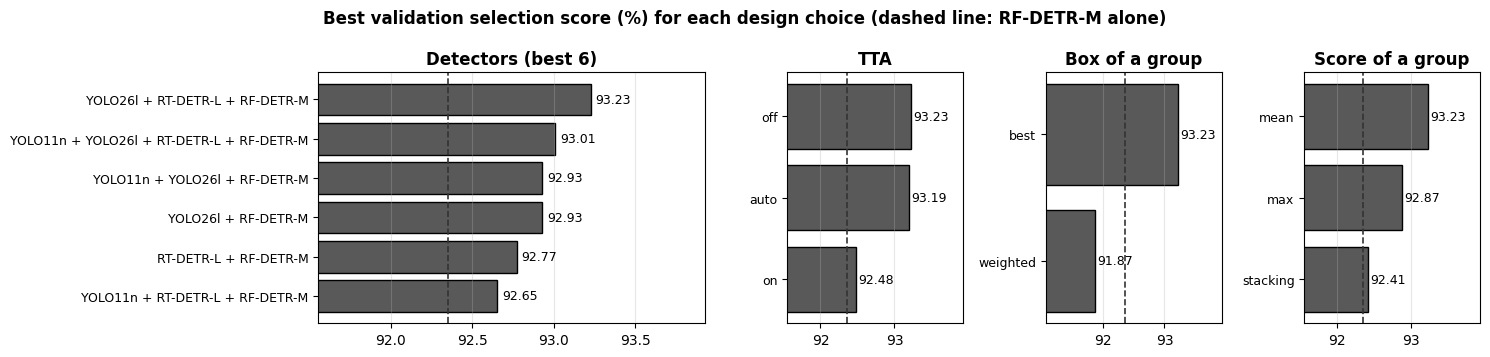

In [22]:
label = lambda r: f"{r.Detectors} | TTA {r.TTA}" + (f" | {r.Box} box | {r.Score}" if r.n > 1 else '')
rf_alone = search[(search.n == 1) & (search.Detectors == 'RF-DETR-M') & (search.TTA == 'off')]
top = pd.concat([search.head(10), rf_alone]).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.barh(range(len(top)), top['Selection score'] * 100, edgecolor='black',
        color=['#f2c200' if i == 0 else ('0.75' if n == 1 else '0.3') for i, n in zip(top.index, top.n)])
for i, r in enumerate(top.itertuples()):
    ax.text(r[-1] * 100 + 0.03, i, f"mAP50-95 {r[7]:.3f}  F1 {r.F1:.3f}", va='center', fontsize=9)
ax.set_yticks(range(len(top))); ax.set_yticklabels([label(r) for r in top.itertuples()], fontsize=9)
ax.set_xlim(top['Selection score'].min() * 100 - 0.3, top['Selection score'].max() * 100 + 0.6)
ax.set_xlabel('Selection score (%) = (mAP50-95 + F1) / 2'); ax.grid(axis='x', alpha=0.3)
ax.set_title('Top 10 configurations on validation vs RF-DETR-M alone', fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_search_top.png', dpi=200); plt.show()

rf = rf_alone['Selection score'].iloc[0] * 100
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={'width_ratios': [2.2, 1, 1, 1]})
for ax, col, title in zip(axes, ['Detectors', 'TTA', 'Box', 'Score'], ['Detectors (best 6)', 'TTA', 'Box of a group', 'Score of a group']):
    d = (ens.groupby(col)['Selection score'].max() * 100).sort_values()
    if col == 'Detectors':
        d = d.tail(6)
    ax.barh(range(len(d)), d.values, color='0.35', edgecolor='black')
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index, fontsize=9)
    for i, v in enumerate(d.values):
        ax.text(v + 0.03, i, f'{v:.2f}', va='center', fontsize=9)
    ax.axvline(rf, color='0.2', ls='--', lw=1.2)
    ax.set_xlim(min(d.min(), rf) - 0.8, d.max() + 0.7); ax.set_title(title, fontweight='bold'); ax.grid(axis='x', alpha=0.3)
fig.suptitle('Best validation selection score (%) for each design choice (dashed line: RF-DETR-M alone)', fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_search_choices.png', dpi=200); plt.show()

## Section 23: Refit Stacking Layer and Run on Test

In [23]:
def run_on_test(cfg, thr):
    members, tta, box, score = cfg
    gv, _ = get_groups(members, tta, 'val'); gt_, ms = get_groups(members, tta, 'test')
    model = None
    if score == 'stacking':
        model = make_stacker().fit(np.array([f['feats'] for g in gv for f in g]), labels_for(gv, val, box))
        scores = [model.predict_proba(np.stack([f['feats'] for f in g]))[:, 1] if g else np.zeros(0) for g in gt_]
    else:
        scores = [np.array([f[score] for f in g]) for g in gt_]
    preds = to_preds(gt_, box, scores)
    r = evaluate(test, preds, thr, [0]); r['ms/image'] = ms
    return r, preds, model

## Section 24: Test Results

In [24]:
results = {}
for n in MODEL_NAMES:  # individual detectors exactly as deployed alone (view A, final threshold)
    results[n] = evaluate(test, [r['A'][n] for r in test], FINAL_CONF[n], [r['tA'][n] for r in test])

reference = (tuple(MODEL_NAMES), 'on', 'weighted', 'stacking')
ref_row = search[search.config.apply(lambda c: c == reference)].iloc[0]
results[f'Initial ensemble design ({len(MODEL_NAMES)} detectors, TTA, weighted box, stacking)'], _, _ = run_on_test(reference, ref_row['Threshold'])

FINAL = f"Best ensemble ({BEST['Detectors']}, TTA {BEST['TTA']}, {BEST['Box']} box, {BEST['Score']})"
results[FINAL], final_preds, final_model = run_on_test(BEST['config'], BEST['Threshold'])

table = pd.DataFrame(results).T
table.to_csv(RESULTS_DIR / 'test_results.csv')
display(table.style.format({'mAP50': '{:.3f}', 'mAP50-95': '{:.3f}', 'Recall': '{:.1%}', 'Precision': '{:.1%}', 'F1': '{:.3f}',
                            'Threshold': '{:.2f}', 'ms/image': '{:.1f}', 'Correct': '{:.0f}', 'Wrong': '{:.0f}', 'FP': '{:.0f}', 'Missed': '{:.0f}'}))

,mAP50,mAP50-95,Recall,Precision,F1,Correct,Wrong,FP,Missed,Threshold,ms/image
YOLO11n,0.956,0.750,90.1%,93.8%,0.919,427,1,27,46,0.50,12.7
YOLO26l,0.956,0.777,93.2%,93.1%,0.932,442,4,29,28,0.50,29.1
RT-DETR-L,0.967,0.775,93.0%,94.2%,0.936,441,3,24,30,0.70,73.9
RF-DETR-M,0.987,0.898,97.3%,96.4%,0.968,461,1,16,12,0.45,45.5
"Initial ensemble design (4 detectors, TTA, weighted box, stacking)",0.988,0.822,95.4%,95.6%,0.955,452,0,21,22,0.56,333.1
"Best ensemble (YOLO26l + RT-DETR-L + RF-DETR-M, TTA off, best box, mean)",0.988,0.894,94.1%,96.5%,0.953,446,2,14,26,0.52,161.0


## Section 25: Ensemble Gain over Best Single Detector

In [25]:
best = max(MODEL_NAMES, key=lambda n: results[n]['mAP50-95'])
cols = ['mAP50', 'mAP50-95', 'Recall', 'Precision', 'F1', 'Correct', 'Wrong', 'FP', 'Missed', 'ms/image']
gain = pd.DataFrame({f'Best single ({best})': table.loc[best, cols], 'Best ensemble': table.loc[FINAL, cols]})
gain['Change'] = gain.iloc[:, 1] - gain.iloc[:, 0]
gain.to_csv(RESULTS_DIR / 'test_gain.csv')
gain.round(4)

,Best single (RF-DETR-M),Best ensemble,Change
mAP50,0.9873,0.9880,0.0006
mAP50-95,0.8977,0.8940,-0.0037
Recall,0.9726,0.9409,-0.0316
Precision,0.9644,0.9654,0.0009
F1,0.9685,0.9530,-0.0155
Correct,461.0000,446.0000,-15.0000
Wrong,1.0000,2.0000,1.0000
FP,16.0000,14.0000,-2.0000
Missed,12.0000,26.0000,14.0000
ms/image,45.5260,161.0147,115.4888


## Section 26: Comparison Figure

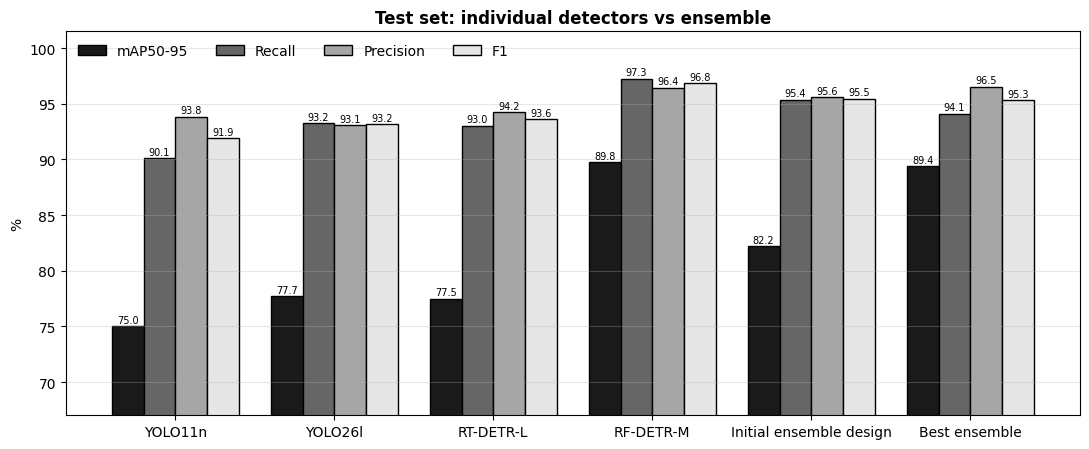

In [26]:
systems = list(results)
short = {s: s.split(' (')[0] if s.startswith('Initial') else s for s in systems}
short[FINAL] = 'Best ensemble'
metrics = ['mAP50-95', 'Recall', 'Precision', 'F1']
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(systems)); w = 0.2
for i, (m, shade) in enumerate(zip(metrics, ['0.1', '0.4', '0.65', '0.9'])):
    vals = [results[s][m] * 100 for s in systems]
    bars = ax.bar(x + (i - 1.5) * w, vals, w, color=shade, edgecolor='black', label=m)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.3, f'{v:.1f}', ha='center', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([short[s] for s in systems], fontsize=10)
lo = min(results[s][m] for s in systems for m in metrics) * 100
ax.set_ylim(max(0, lo - 8), 101.5); ax.set_ylabel('%'); ax.grid(axis='y', alpha=0.3); ax.legend(frameon=False, ncol=4, loc='upper left')
ax.set_title('Test set: individual detectors vs ensemble', fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_comparison.png', dpi=200); plt.show()

## Section 27: Accuracy vs Inference Time

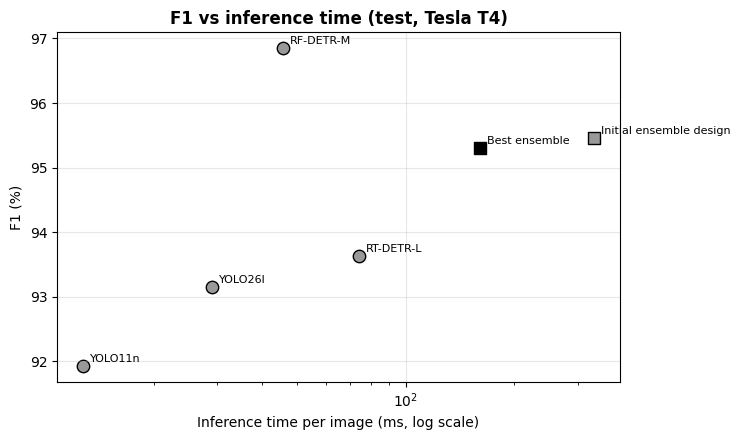

In [27]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for s in systems:
    r = results[s]
    ax.scatter(r['ms/image'], r['F1'] * 100, s=80, marker='s' if s not in MODEL_NAMES else 'o',
               color='black' if s == FINAL else '0.6', edgecolor='black')
    ax.annotate(short[s], (r['ms/image'], r['F1'] * 100), fontsize=8, xytext=(5, 3), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('Inference time per image (ms, log scale)'); ax.set_ylabel('F1 (%)')
ax.grid(alpha=0.3); ax.set_title('F1 vs inference time (test, Tesla T4)', fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_speed.png', dpi=200); plt.show()

## Section 28: Per-Class Results

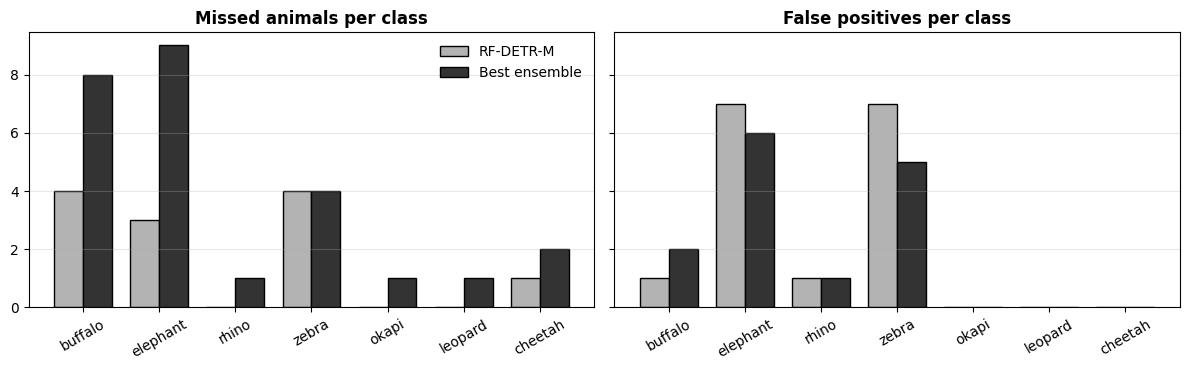

In [28]:
def per_class(records, preds, thr):
    rows = {c: {'Correct': 0, 'Wrong': 0, 'FP': 0, 'Missed': 0} for c in CLASS_NAMES}
    for r, (b, s, c) in zip(records, preds):
        k = s >= thr
        out, missed = match(b[k], s[k], c[k], r['gt'], r['gcls'])
        for o, ci in zip(out, c[k]):
            rows[CLASS_NAMES[ci]][{'correct': 'Correct', 'wrong': 'Wrong', 'fp': 'FP'}[o]] += 1
        for j in np.where(missed)[0]:
            rows[CLASS_NAMES[r['gcls'][j]]]['Missed'] += 1
    df = pd.DataFrame(rows).T
    df['Op. acc.'] = df.Correct / (df.Correct + df.Wrong + df.FP).clip(lower=1)
    return df

pc_best = per_class(test, [r['A'][best] for r in test], FINAL_CONF[best])
pc_final = per_class(test, final_preds, BEST['Threshold'])
pc = pd.concat({best: pc_best, 'Best ensemble': pc_final}, axis=1)
pc.to_csv(RESULTS_DIR / 'test_per_class.csv')
display(pc.style.format({(m, 'Op. acc.'): '{:.1%}' for m in [best, 'Best ensemble']}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x = np.arange(len(CLASS_NAMES)); w = 0.38
for ax, col, title in [(axes[0], 'Missed', 'Missed animals per class'), (axes[1], 'FP', 'False positives per class')]:
    ax.bar(x - w / 2, pc_best[col], w, color='0.7', edgecolor='black', label=best)
    ax.bar(x + w / 2, pc_final[col], w, color='0.2', edgecolor='black', label='Best ensemble')
    ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=30); ax.set_title(title, fontweight='bold'); ax.grid(axis='y', alpha=0.3)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_per_class_errors.png', dpi=200); plt.show()

## Section 29: Example Images

Test images with fewer errors: ensemble 8, RF-DETR-M 17, equal 306


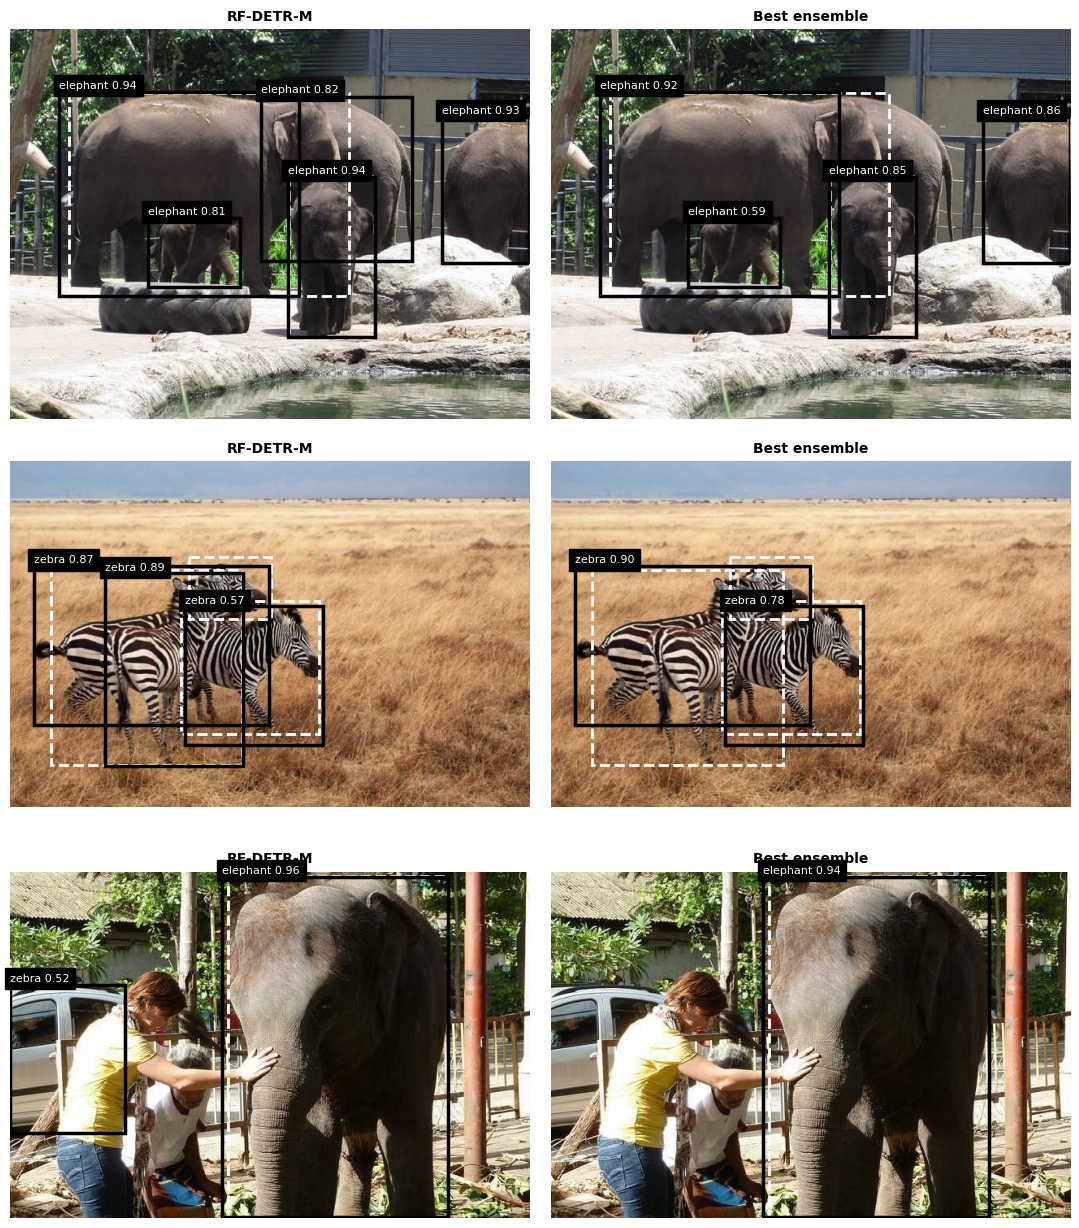

In [29]:
def draw(ax, rec, b, s, c, title):
    img = cv2.cvtColor(cv2.imread(rec['image']), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.axis('off'); ax.set_title(title, fontsize=10, fontweight='bold')
    for g in rec['gt']:
        ax.add_patch(plt.Rectangle(g[:2], *(g[2:] - g[:2]), fill=False, ec='white', lw=2, ls='--'))
    for bb, ss, cc in zip(b, s, c):
        ax.add_patch(plt.Rectangle(bb[:2], *(bb[2:] - bb[:2]), fill=False, ec='black', lw=2.5))
        ax.text(bb[0], bb[1] - 4, f'{CLASS_NAMES[cc]} {ss:.2f}', fontsize=8, color='white', backgroundcolor='black')

def errors(rec, pred, thr):
    b, s, c = pred; k = s >= thr
    out, missed = match(b[k], s[k], c[k], rec['gt'], rec['gcls'])
    return int((out != 'correct').sum() + missed.sum()), (b[k], s[k], c[k])

diff = []
for i, r in enumerate(test):
    e_b, pb = errors(r, r['A'][best], FINAL_CONF[best]); e_f, pf = errors(r, final_preds[i], BEST['Threshold'])
    diff.append((e_b - e_f, i, pb, pf))
better = sum(d[0] > 0 for d in diff); worse = sum(d[0] < 0 for d in diff)
print(f'Test images with fewer errors: ensemble {better}, {best} {worse}, equal {len(diff) - better - worse}')
cands = sorted([d for d in diff if d[0] > 0], key=lambda t: -t[0])[:3]
if cands:
    fig, axes = plt.subplots(len(cands), 2, figsize=(11, 4.2 * len(cands)), squeeze=False)
    for row, (_, i, pb, pf) in enumerate(cands):
        draw(axes[row, 0], test[i], *pb, best); draw(axes[row, 1], test[i], *pf, 'Best ensemble')
    plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_examples.png', dpi=150); plt.show()

## Section 30: Save Configuration and Download

In [30]:
import json
members, tta, box, score = BEST['config']
config = {'detectors': list(members), 'tta': {n: (tta if tta in ('on', 'off') else TTA_AUTO[n]) for n in members},
          'box_mode': box, 'score_mode': score, 'threshold': float(BEST['Threshold']), 'candidate_conf': CANDIDATE_CONF,
          'nms_iou': NMS_IOU, 'tta_iou': TTA_IOU, 'cluster_iou': CLUSTER_IOU, 'quality': QUALITY, 'rank': RANK,
          'class_names': CLASS_NAMES, 'final_conf': FINAL_CONF,
          'validation': {k: float(BEST[k]) for k in ['mAP50-95', 'mAP50', 'F1', 'Recall', 'Precision', 'Selection score']}}
json.dump(config, open(RESULTS_DIR / 'ensemble_config.json', 'w'), indent=2)
if final_model is not None:
    joblib.dump({'model': final_model, 'config': config}, RESULTS_DIR / 'ensemble_stacker.joblib')
print(json.dumps(config, indent=2))

EXPORT = Path('/content/ensemble_results_export')
shutil.rmtree(EXPORT, ignore_errors=True); EXPORT.mkdir()
for f in RESULTS_DIR.iterdir():
    if f.is_dir():
        shutil.copytree(f, EXPORT / f.name)
    elif f.suffix != '.pkl':
        shutil.copy2(f, EXPORT / f.name)
archive = shutil.make_archive('/content/ensemble_results', 'zip', EXPORT)
files.download(archive)

{
  "detectors": [
    "YOLO26l",
    "RT-DETR-L",
    "RF-DETR-M"
  ],
  "tta": {
    "YOLO26l": "off",
    "RT-DETR-L": "off",
    "RF-DETR-M": "off"
  },
  "box_mode": "best",
  "score_mode": "mean",
  "threshold": 0.52,
  "candidate_conf": 0.02,
  "nms_iou": 0.7,
  "tta_iou": 0.55,
  "cluster_iou": 0.55,
  "quality": {
    "YOLO11n": 0.7577421204899629,
    "YOLO26l": 0.7826400343186448,
    "RT-DETR-L": 0.7935969488049792,
    "RF-DETR-M": 0.8931186182474482
  },
  "rank": [
    "RF-DETR-M",
    "RT-DETR-L",
    "YOLO26l",
    "YOLO11n"
  ],
  "class_names": [
    "buffalo",
    "elephant",
    "rhino",
    "zebra",
    "okapi",
    "leopard",
    "cheetah"
  ],
  "final_conf": {
    "YOLO11n": 0.5,
    "YOLO26l": 0.5,
    "RT-DETR-L": 0.7,
    "RF-DETR-M": 0.45
  },
  "validation": {
    "mAP50-95": 0.8977408469028907,
    "mAP50": 0.9856731530589801,
    "F1": 0.9668141592920354,
    "Recall": 0.9562363238512035,
    "Precision": 0.9776286353467561,
    "Selection score": 0.9322

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>